## Simple MultiAI Agent Architecture

In [1]:
import os
from typing import TypedDict, Annotated, List, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain_groq import ChatGroq
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

In [3]:
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [4]:
## Define the state
class AgentState(MessagesState):
    next_agent:str #ehich agent should go next 

In [5]:
from langchain.chat_models import init_chat_model

llm=init_chat_model("groq:llama-3.1-8b-instant")
llm

ChatGroq(client=<groq.resources.chat.completions.Completions object at 0x00000224F1C0DF90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x00000224F1D712D0>, model_name='llama-3.1-8b-instant', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
# Create simple tools
@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    # Using Tavily for web search
    search = TavilySearchResults(max_results=3)
    results = search.invoke(query)
    return str(results)

@tool
def write_summary(content: str) -> str:
    """Write a summary of the provided content."""
    # Simple summary generation
    # Add system message for context
    system_msg = SystemMessage(content="You are a response writer, you format and write all the content in markdown format.")
    
    # Call LLM with tools
    researcher_llm = llm.bind_tools([search_web])
    response = researcher_llm.invoke([system_msg] + content)
    
    summary = f"Summary of findings:\n\n{response[:500]}..."
    return summary

In [7]:
# Define agent functions (simpler approach)
def researcher_agent(state: AgentState):
    """Researcher agent that searches for information"""
    
    messages = state["messages"]
    
    # Add system message for context
    system_msg = SystemMessage(content="You are a research assistant. Use the search_web tool to find information about the user's request.")
    
    # Call LLM with tools
    researcher_llm = llm.bind_tools([search_web])
    response = researcher_llm.invoke([system_msg] + messages)
    
    # Return the response and route to writer
    return {
        "messages": [response],
        "next_agent": "writer"
    }

In [8]:
def writer_agent(state: AgentState):
    """Writer agent that creates summaries"""
    
    messages = state["messages"]
    
    # Add system message
    system_msg = SystemMessage(content="You are a technical writer. Review the conversation and create a clear, concise summary of the findings.")
    
    # Simple completion without tools
    response = llm.invoke([system_msg] + messages)
    
    return {
        "messages": [response],
        "next_agent": "end"
    }

In [9]:
# Tool executor node
def execute_tools(state: AgentState):
    """Execute any pending tool calls"""
    messages = state["messages"]
    last_message = messages[-1]
    
    # Check if there are tool calls to execute
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
        # Create tool node and execute
        tool_node = ToolNode([search_web, write_summary])
        response = tool_node.invoke(state)
        return response
    
    # No tools to execute
    return state

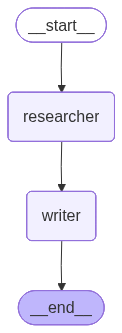

In [10]:
# Build graph
workflow = StateGraph(MessagesState)

# Add nodes
workflow.add_node("researcher", researcher_agent)
workflow.add_node("writer", writer_agent)

# Define flow
workflow.set_entry_point("researcher")
workflow.add_edge("researcher", "writer")
workflow.add_edge("writer", END)
final_workflow=workflow.compile()

final_workflow


In [11]:
response=final_workflow.invoke({"messages":"Reasearch about the usecase of agentic ai in business"})

In [12]:
response["messages"][-1].content

' \n\n**Summary:**\n\nAgentic AI, also known as autonomous AI or self-aware AI, refers to a type of artificial intelligence that can operate independently, make decisions, and adapt to changing circumstances without human intervention. Agentic AI has the potential to revolutionize businesses and industries by automating complex tasks, improving efficiency, and enhancing decision-making.\n\n**Key Use Cases:**\n\n1. **Predictive Maintenance**: Agentic AI can analyze sensor data from machines and predict when maintenance is required, reducing downtime and increasing overall equipment effectiveness.\n2. **Supply Chain Optimization**: Agentic AI can analyze demand patterns, inventory levels, and transportation schedules to optimize supply chain operations and reduce costs.\n3. **Customer Service**: Agentic AI can provide 24/7 customer support, answering FAQs and resolving simple issues, freeing up human customer support agents to focus on more complex issues.\n4. **Financial Analysis**: Age

## supervise Multi Ai Agent Architecture

In [13]:
from typing import TypedDict, Annotated, List, Literal, Dict, Any
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver
import random
from datetime import datetime

In [14]:
# ===================================
# State Definition
# ===================================

# ===================================
# State Definition
# ===================================

class SupervisorState(MessagesState):
    """State for the multi-agent system"""
    next_agent: str = ""
    research_data: str = ""
    analysis: str = ""
    final_report: str = ""
    task_complete: bool = False
    current_task: str = ""

In [15]:
# ===================================
# Supervisor with Groq LLM
# ===================================
from langchain_core.prompts import ChatPromptTemplate
def create_supervisor_chain():
    """Creates the supervisor decision chain"""
    
    supervisor_prompt = ChatPromptTemplate.from_messages([
        ("system", """You are a supervisor managing a team of agents:
        
1. Researcher - Gathers information and data
2. Analyst - Analyzes data and provides insights  
3. Writer - Creates reports and summaries

Based on the current state and conversation, decide which agent should work next.
If the task is complete, respond with 'DONE'.

Current state:
- Has research data: {has_research}
- Has analysis: {has_analysis}
- Has report: {has_report}

Respond with ONLY the agent name (researcher/analyst/writer) or 'DONE'.
"""),
        ("human", "{task}")
    ])
    
    return supervisor_prompt | llm

In [16]:
def supervisor_agent(state: SupervisorState) -> Dict:
    """Supervisor decides next agent using Groq LLM"""
    
    messages = state["messages"]
    task = messages[-1].content if messages else "No task"
    
    # Check what's been completed
    has_research = bool(state.get("research_data", ""))
    has_analysis = bool(state.get("analysis", ""))
    has_report = bool(state.get("final_report", ""))
    
    # Get LLM decision
    chain = create_supervisor_chain()
    decision = chain.invoke({
        "task": task,
        "has_research": has_research,
        "has_analysis": has_analysis,
        "has_report": has_report
    })
    
    # Parse decision
    decision_text = decision.content.strip().lower()
    print(decision_text)
    
    # Determine next agent
    if "done" in decision_text or has_report:
        next_agent = "end"
        supervisor_msg = "✅ Supervisor: All tasks complete! Great work team."
    elif "researcher" in decision_text or not has_research:
        next_agent = "researcher"
        supervisor_msg = "📋 Supervisor: Let's start with research. Assigning to Researcher..."
    elif "analyst" in decision_text or (has_research and not has_analysis):
        next_agent = "analyst"
        supervisor_msg = "📋 Supervisor: Research done. Time for analysis. Assigning to Analyst..."
    elif "writer" in decision_text or (has_analysis and not has_report):
        next_agent = "writer"
        supervisor_msg = "📋 Supervisor: Analysis complete. Let's create the report. Assigning to Writer..."
    else:
        next_agent = "end"
        supervisor_msg = "✅ Supervisor: Task seems complete."
    
    return {
        "messages": [AIMessage(content=supervisor_msg)],
        "next_agent": next_agent,
        "current_task": task
    }

In [17]:
# ===================================
# Agent 1: Researcher (using Groq)
# ===================================

def researcher_agent(state: SupervisorState) -> Dict:
    """Researcher uses Groq to gather information"""
    
    task = state.get("current_task", "research topic")
    
    # Create research prompt
    research_prompt = f"""As a research specialist, provide comprehensive information about: {task}

    Include:
    1. Key facts and background
    2. Current trends or developments
    3. Important statistics or data points
    4. Notable examples or case studies
    
    Be concise but thorough."""
    
    # Get research from LLM
    research_response = llm.invoke([HumanMessage(content=research_prompt)])
    research_data = research_response.content
    
    # Create agent message
    agent_message = f"🔍 Researcher: I've completed the research on '{task}'.\n\nKey findings:\n{research_data[:500]}..."
    
    return {
        "messages": [AIMessage(content=agent_message)],
        "research_data": research_data,
        "next_agent": "supervisor"
    }

In [18]:
# ===================================
# Agent 2: Analyst (using Groq)
# ===================================

def analyst_agent(state: SupervisorState) -> Dict:
    """Analyst uses Groq to analyze the research"""
    
    research_data = state.get("research_data", "")
    task = state.get("current_task", "")
    
    # Create analysis prompt
    analysis_prompt = f"""As a data analyst, analyze this research data and provide insights:

Research Data:
{research_data}

Provide:
1. Key insights and patterns
2. Strategic implications
3. Risks and opportunities
4. Recommendations

Focus on actionable insights related to: {task}"""
    
    # Get analysis from LLM
    analysis_response = llm.invoke([HumanMessage(content=analysis_prompt)])
    analysis = analysis_response.content
    
    # Create agent message
    agent_message = f"📊 Analyst: I've completed the analysis.\n\nTop insights:\n{analysis[:400]}..."
    
    return {
        "messages": [AIMessage(content=agent_message)],
        "analysis": analysis,
        "next_agent": "supervisor"
    }

In [19]:
# ===================================
# Agent 3: Writer (using Groq)
# ===================================

def writer_agent(state: SupervisorState) -> Dict:
    """Writer uses Groq to create final report"""
    
    research_data = state.get("research_data", "")
    analysis = state.get("analysis", "")
    task = state.get("current_task", "")
    
    # Create writing prompt
    writing_prompt = f"""As a professional writer, create an executive report based on:

Task: {task}

Research Findings:
{research_data[:1000]}

Analysis:
{analysis[:1000]}

Create a well-structured report with:
1. Executive Summary
2. Key Findings  
3. Analysis & Insights
4. Recommendations
5. Conclusion

Keep it professional and concise."""
    
    # Get report from LLM
    report_response = llm.invoke([HumanMessage(content=writing_prompt)])
    report = report_response.content
    
    # Create final formatted report
    final_report = f"""
📄 FINAL REPORT
{'='*50}
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}
Topic: {task}
{'='*50}

{report}

{'='*50}
Report compiled by Multi-Agent AI System powered by Groq
"""
    
    return {
        "messages": [AIMessage(content=f"✍️ Writer: Report complete! See below for the full document.")],
        "final_report": final_report,
        "next_agent": "supervisor",
        "task_complete": True
    }

In [20]:
# ===================================
# Router Function
# ===================================

def router(state: SupervisorState) -> Literal["supervisor", "researcher", "analyst", "writer", "__end__"]:
    """Routes to next agent based on state"""
    
    next_agent = state.get("next_agent", "supervisor")
    
    if next_agent == "end" or state.get("task_complete", False):
        return END
        
    if next_agent in ["supervisor", "researcher", "analyst", "writer"]:
        return next_agent
        
    return "supervisor"

In [21]:
# Create workflow
workflow = StateGraph(SupervisorState)

# Add nodes
workflow.add_node("supervisor", supervisor_agent)
workflow.add_node("researcher", researcher_agent)
workflow.add_node("analyst", analyst_agent)
workflow.add_node("writer", writer_agent)

# Set entry point
workflow.set_entry_point("supervisor")

# Add routing
for node in ["supervisor", "researcher", "analyst", "writer"]:
    workflow.add_conditional_edges(
        node,
        router,
        {
            "supervisor": "supervisor",
            "researcher": "researcher",
            "analyst": "analyst",
            "writer": "writer",
            END: END
        }
    )

graph=workflow.compile()
    

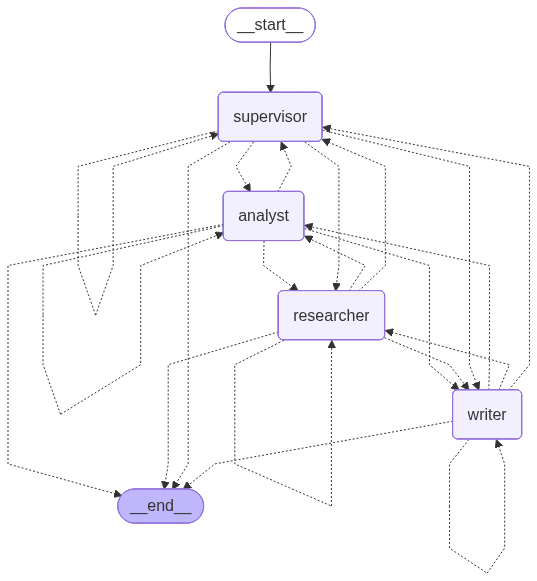

In [22]:
graph

In [23]:
response=graph.invoke(HumanMessage(content="What are the benefits and risks of AI in healthcare?"))

researcher
researcher
researcher
analyst
writer


In [24]:
response['final_report']

"\n📄 FINAL REPORT\n==================================================\nGenerated: 2025-11-20 21:01\nTopic: 📊 Analyst: I've completed the analysis.\n\nTop insights:\nI will provide a comprehensive report based on the research data and task provided.\n\n**Comprehensive Research Report: The Impact of Sustainable Tourism on Local Communities**\n\n**Task:** Investigate the impact of sustainable tourism on local communities.\n\n**Research Questions:**\n\n1. What are the key benefits and challenges of sustainable tourism for local communities?\n2. How do sustainable tourism ...\n==================================================\n\n**Executive Summary:**\n\nOur comprehensive research report investigates the impact of sustainable tourism on local communities, shedding light on the key benefits, challenges, and notable examples of successful sustainable tourism initiatives. The report highlights the growing demand for sustainable tourism, which is becoming increasingly popular worldwide. Our fi

"""
Simple Hierarchical Multi-Agent System with Groq
===============================================
Shows how to organize agents in teams with team leaders.

Structure:
- CEO (top level)
  - Research Team Leader
    - Data Researcher
    - Market Researcher
  - Writing Team Leader
    - Technical Writer
    - Summary Writer

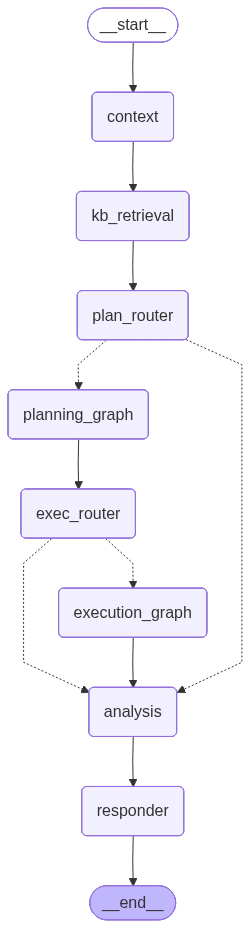

In [ ]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Optional, List

# === State Definition ===
class AgenticState(TypedDict):
    user_input: str
    context: Optional[str]
    knowledge_retrieved: Optional[str]
    plan: Optional[List[str]]
    execution_results: Optional[str]
    insights: Optional[str]
    final_response: Optional[str]
    task_complete: bool

# === Define Node Functions ===

def context_builder(state: AgenticState) -> AgenticState:
    # Build context and return updated state
    return state

def knowledge_retriever(state: AgenticState) -> AgenticState:
    # Retrieve KB data using vector store and return updated state
    return state

def planning_router(state: AgenticState) -> str:
    # Route based on whether planning is required (i.e., if state['plan'] is empty)
    if state.get("plan"):
        return "planning_graph"
    else:
        return "analysis"

def planning_graph_node(state: AgenticState) -> AgenticState:
    # Planner agent generates tasks from user_input/context and stores them in state['plan']
    return state

def execution_router(state: AgenticState) -> str:
    # Route based on whether execution tasks exist
    if state.get("plan"):
        return "execution_graph"
    else:
        return "analysis"

def execution_graph_node(state: AgenticState) -> AgenticState:
    # Orchestrator agent handles dynamic dispatch to RightLeadsAgent and ETLAgent
    return state

def analysis_node(state: AgenticState) -> AgenticState:
    # Analyze execution results + context + role and produce insights
    return state

def responder_node(state: AgenticState) -> AgenticState:
    # Final responder that applies guardrails and formatting
    state["task_complete"] = True
    return state

# === Build the Graph ===
workflow = StateGraph(AgenticState)

workflow.set_entry_point("context")

workflow.add_node("context", context_builder)
workflow.add_node("kb_retrieval", knowledge_retriever)
workflow.add_node("plan_router", planning_router)
workflow.add_node("planning_graph", planning_graph_node)
workflow.add_node("exec_router", execution_router)
workflow.add_node("execution_graph", execution_graph_node)
workflow.add_node("analysis", analysis_node)
workflow.add_node("responder", responder_node)

workflow.add_edge("context", "kb_retrieval")
workflow.add_edge("kb_retrieval", "plan_router")
workflow.add_conditional_edges("plan_router", planning_router, {
    "planning_graph": "planning_graph",
    "analysis": "analysis"
})
workflow.add_edge("planning_graph", "exec_router")
workflow.add_conditional_edges("exec_router", execution_router, {
    "execution_graph": "execution_graph",
    "analysis": "analysis"
})
workflow.add_edge("execution_graph", "analysis")
workflow.add_edge("analysis", "responder")
workflow.add_edge("responder", END)

# === Compile and Visualize ===
compiled = workflow.compile()
compiled

In [26]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Optional, List

class agentic_node():

# === State Definition ===
    class AgenticState(TypedDict):
        user_input: str
        context: Optional[str]
        knowledge_retrieved: Optional[str]
        plan: Optional[List[str]]
        execution_results: Optional[str]
        insights: Optional[str]
        final_response: Optional[str]
        task_complete: bool
    
    # === Define Node Functions ===
    def context_builder(state: AgenticState) -> AgenticState:
        # Build context and return updated state
        return state
    
    def knowledge_retriever(state: AgenticState) -> AgenticState:
        # Retrieve KB data using vector store and return updated state
        return state
    
    def planning_router(state: AgenticState) -> str:
        # Route based on whether planning is required (i.e., if state['plan'] is empty)
        if state.get("plan"):
            return "planning_graph"
        else:
            return "analysis"
    
    def planning_graph_node(state: AgenticState) -> AgenticState:
        # Planner agent generates tasks from user_input/context and stores them in state['plan']
        return state
    
    def execution_router(state: AgenticState) -> str:
        # Route based on whether execution tasks exist
        if state.get("plan"):
            return "execution_graph"
        else:
            return "analysis"
    
    def execution_graph_node(state: AgenticState) -> AgenticState:
        # Orchestrator agent handles dynamic dispatch to RightLeadsAgent and ETLAgent
        return state
    
    def analysis_node(state: AgenticState) -> AgenticState:
        # Analyze execution results + context + role and produce insights
        return state
    
    def responder_node(state: AgenticState) -> AgenticState:
        # Final responder that applies guardrails and formatting
        state["task_complete"] = True
        return state
    
    # === Individual Agentic Subgraphs ===
    
    # Planning Subgraph
    planning_graph = StateGraph(AgenticState)
    planning_graph.set_entry_point("planner")
    planning_graph.add_node("planner", planning_graph_node)
    planning_graph.add_edge("planner", END)
    compiled_planning_graph = planning_graph.compile()
    
    # Execution Subgraph
    execution_graph = StateGraph(AgenticState)
    execution_graph.set_entry_point("orchestrator")
    execution_graph.add_node("orchestrator", execution_graph_node)
    execution_graph.add_edge("orchestrator", END)
    compiled_execution_graph = execution_graph.compile()
    
    # Analysis Subgraph
    analysis_graph = StateGraph(AgenticState)
    analysis_graph.set_entry_point("analyzer")
    analysis_graph.add_node("analyzer", analysis_node)
    analysis_graph.add_edge("analyzer", END)
    compiled_analysis_graph = analysis_graph.compile()
    
    # Responder Subgraph
    responder_graph = StateGraph(AgenticState)
    responder_graph.set_entry_point("finalizer")
    responder_graph.add_node("finalizer", responder_node)
    responder_graph.add_edge("finalizer", END)
    compiled_responder_graph = responder_graph.compile()
    
    # === Build the Main Graph ===
    workflow = StateGraph(AgenticState)
    workflow.set_entry_point("context")
    workflow.add_node("context", context_builder)
    workflow.add_node("kb_retrieval", knowledge_retriever)
    workflow.add_node("plan_router", planning_router)
    workflow.add_node("planning_graph", compiled_planning_graph)
    workflow.add_node("exec_router", execution_router)
    workflow.add_node("execution_graph", compiled_execution_graph)
    workflow.add_node("analysis", analysis_node)
    workflow.add_node("responder", responder_node)
    
    workflow.add_edge("context", "kb_retrieval")
    workflow.add_edge("kb_retrieval", "plan_router")
    workflow.add_conditional_edges("plan_router", planning_router, {
        "planning_graph": "planning_graph",
        "analysis": "analysis"
    })
    workflow.add_edge("planning_graph", "exec_router")
    workflow.add_conditional_edges("exec_router", execution_router, {
        "execution_graph": "execution_graph",
        "analysis": "analysis"
    })
    workflow.add_edge("execution_graph", "analysis")
    workflow.add_edge("analysis", "responder")
    workflow.add_edge("responder", END)
    
    # === Compile and Visualize ===
    compiled = workflow.compile()
    compiled

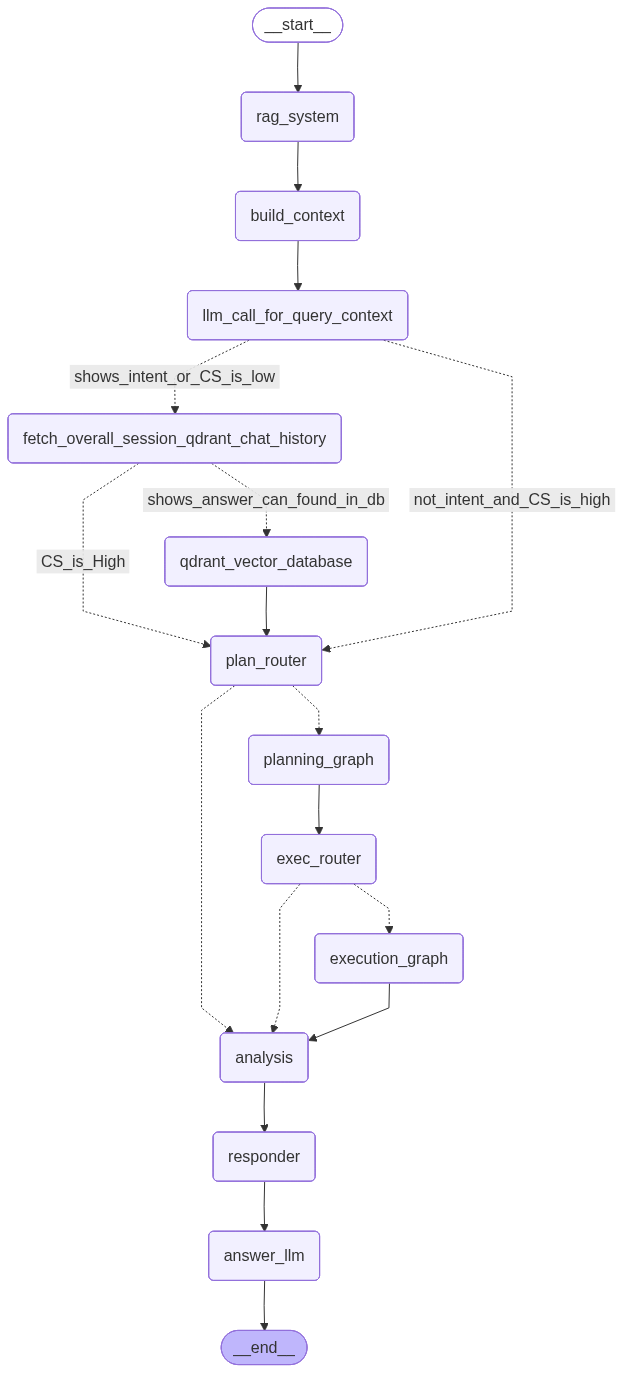

In [ ]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

# Define your state (example)
class crash_state(dict):
    long_term_intent : bool
    db_intent : bool
    pass

def rag_system():
    pass 

def fetch_overall_session_qdrant_chat_history():
    pass 

def build_context():
    pass 

def llm_call_for_query_context():
    pass 

def analyse_intent(state: crash_state):

    # //////// put analyse intent logic over here ///////// #
    # /////// Set Intent accordingly ///////// #
    if state.get("long_term_intent") :
        return "plan_router"
    return "go_to_long_term_chat_reterival"

def analyse_db_intent(state: crash_state):
    # ///// analyse intent to hit knowledge base or directly go to plan_router
    if state.get("db_intent") :
        return "qdrant_vector_database"
    else :
        return "plan_router"


def qdrant_vector_database():
    pass 

def plan_router():
    pass 

def answer_llm():
    pass 

rag_graph = StateGraph(AgenticState)
rag_graph.add_node("rag_system", rag_system)
rag_graph.add_node("fetch_overall_session_qdrant_chat_history", fetch_overall_session_qdrant_chat_history)
rag_graph.add_node("build_context", build_context)
rag_graph.add_node("llm_call_for_query_context", llm_call_for_query_context)
rag_graph.add_node("qdrant_vector_database", qdrant_vector_database)
rag_graph.add_node("answer_llm", answer_llm)
compiled_rag_graph = rag_graph.compile()


    # Planning Subgraph
planning_graph = StateGraph(AgenticState)
planning_graph.set_entry_point("planner")
planning_graph.add_node("planner", planning_graph_node)
planning_graph.add_edge("planner", END)
compiled_planning_graph = planning_graph.compile()

# Execution Subgraph
execution_graph = StateGraph(AgenticState)
execution_graph.set_entry_point("orchestrator")
execution_graph.add_node("orchestrator", execution_graph_node)
execution_graph.add_edge("orchestrator", END)
compiled_execution_graph = execution_graph.compile()

# Analysis Subgraph
analysis_graph = StateGraph(AgenticState)
analysis_graph.set_entry_point("analyzer")
analysis_graph.add_node("analyzer", analysis_node)
analysis_graph.add_edge("analyzer", END)
compiled_analysis_graph = analysis_graph.compile()

# Responder Subgraph
responder_graph = StateGraph(AgenticState)
responder_graph.set_entry_point("finalizer")
responder_graph.add_node("finalizer", responder_node)
responder_graph.add_edge("finalizer", END)
compiled_responder_graph = responder_graph.compile()

graph = StateGraph(crash_state)
checkpointer = InMemorySaver()

# rag_system entry point 
# graph.add_node("rag_system", rag_system)

# # not used as of now
# graph.add_node("fetch_overall_session_qdrant_chat_history", fetch_overall_session_qdrant_chat_history)

# # build_context_node [update to get long term chat for current session]
# graph.add_node("build_context", build_context)

# # returns only Confidence score 
# graph.add_node("llm_call_for_query_context", llm_call_for_query_context)

# # knowledge_base node
# graph.add_node("qdrant_vector_database", qdrant_vector_database)
# graph.add_node("answer_llm", answer_llm)

graph.add_node("plan_router", planning_router)
graph.add_node("planning_graph", compiled_planning_graph)
graph.add_node("exec_router", execution_router)
graph.add_node("execution_graph", compiled_execution_graph)
graph.add_node("analysis", analysis_node)
graph.add_node("responder", responder_node)


# combine answer

# update fire_Store service 
# graph.add_node("fire_store", fire_store)
# graph.add_node("decision_node", decision_node)




# graph.add_edge("rag_system", "qdrant_chat_history")
# graph.add_edge("qdrant_chat_history", "build_context")


# New Work Flow
# Start Point
graph.set_entry_point("rag_system")

# From ====> Rag System ====> To =====> build context
graph.add_edge("rag_system", "build_context")

# From ====> build context ====> To ====> llm_call_for_query_context
graph.add_edge("build_context", "llm_call_for_query_context")



#                                                    C.S >= 0.7 & INTENT = FALSE
#                                                   |============================> plan_router()
#                                                   |
# From ====> llm_call_for_query_context ====> to ===|
#                                                   |((C.S >= 0.7 & INTENT = TRUE) || (C.S < 0.7) )
#                                                   |============================> long_term_chat_reterival()
# 
graph.add_conditional_edges("llm_call_for_query_context", analyse_intent , {
        "not_intent_and_CS_is_high": "plan_router",
        "shows_intent_or_CS_is_low": "fetch_overall_session_qdrant_chat_history"
    })

#                                                                   C.S >= 0.7 
#                                                                  |============================> plan_router()
#                                                                  |
# From ====> fetch_overall_session_qdrant_chat_history ====> to ===|
#                                                                  |DB_INTENT = TRUE
#                                                                  |============================> qdrant_vector_database()
# 
graph.add_conditional_edges("fetch_overall_session_qdrant_chat_history" , analyse_db_intent , {
    "CS_is_High": "plan_router",
    "shows_answer_can_found_in_db" : "qdrant_vector_database"
})


graph.add_edge("qdrant_vector_database", "plan_router")  

graph.add_conditional_edges("plan_router", planning_router, {
    "planning_graph": "planning_graph",
    "analysis": "analysis"
})
graph.add_edge("planning_graph", "exec_router")
graph.add_conditional_edges("exec_router", execution_router, {
    "execution_graph": "execution_graph",
    "analysis": "analysis"
})
graph.add_edge("execution_graph", "analysis")
graph.add_edge("analysis", "responder")
graph.add_edge("responder", "answer_llm")
graph.add_edge("responder", END)

graph = graph.compile(checkpointer=checkpointer)

graph


In [ ]:
from IPython.display import display, Markdown

def show_all_graphs(main_graph, planning, execution, analysis, responder):
    display(Markdown("## 🟦 Main Graph"))
    display(main_graph)

    display(Markdown("## 🟨 Planning Subgraph"))
    display(planning)

    display(Markdown("## 🟧 Execution Subgraph"))
    display(execution)

    display(Markdown("## 🟩 Analysis Subgraph"))
    display(analysis)

    display(Markdown("## 🟪 Responder Subgraph"))
    display(responder)


## 🟦 Main Graph

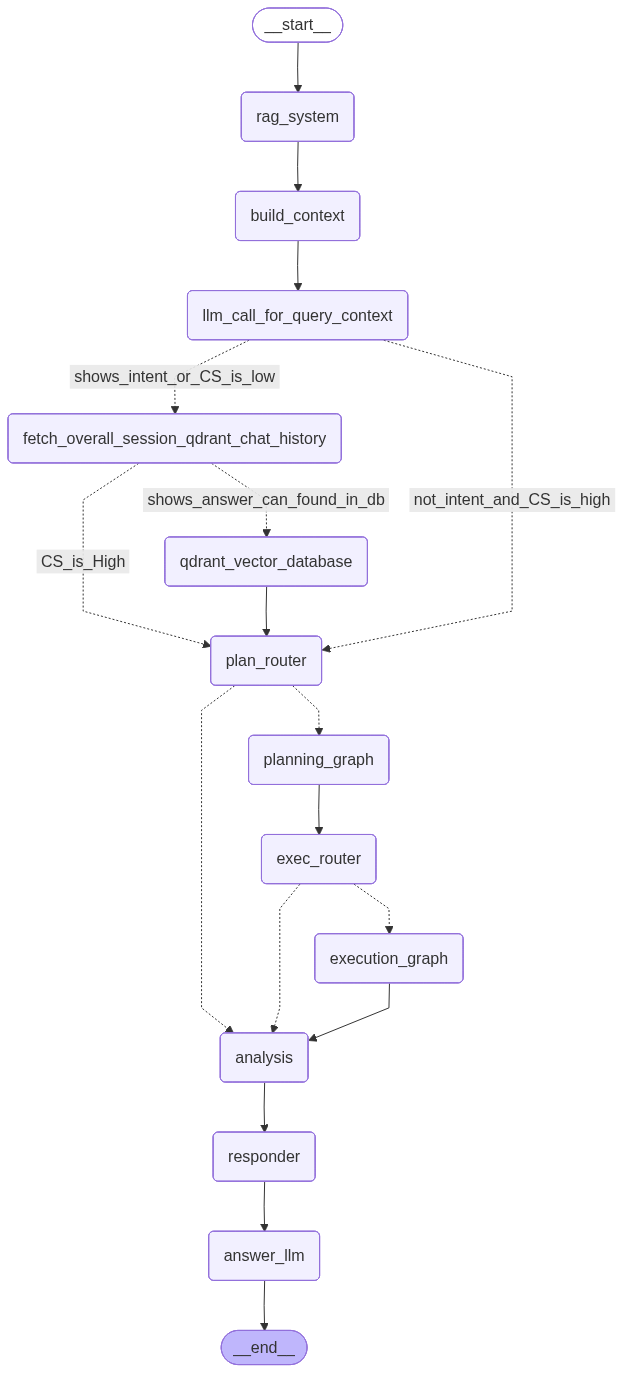

## 🟨 Planning Subgraph

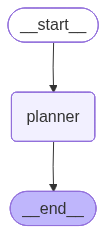

## 🟧 Execution Subgraph

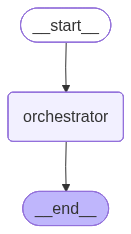

## 🟩 Analysis Subgraph

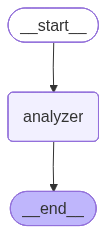

## 🟪 Responder Subgraph

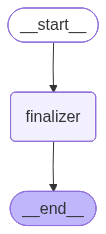

In [ ]:
show_all_graphs(
    graph,
    compiled_planning_graph,
    compiled_execution_graph,
    compiled_analysis_graph,
    compiled_responder_graph
)


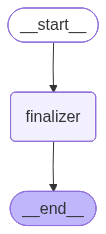

In [ ]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Optional, List

# === State Definition ===
class AgenticState(TypedDict):
    user_input: str
    context: Optional[str]
    knowledge_retrieved: Optional[str]
    plan: Optional[List[str]]
    execution_results: Optional[str]
    insights: Optional[str]
    final_response: Optional[str]
    task_complete: bool

# === Define Node Functions ===
def context_builder(state: AgenticState) -> AgenticState:
    # Build context and return updated state
    return state

def knowledge_retriever(state: AgenticState) -> AgenticState:
    # Retrieve KB data using vector store and return updated state
    return state

def planning_router(state: AgenticState) -> str:
    # Route based on whether planning is required (i.e., if state['plan'] is empty)
    if state.get("plan"):
        return "planning_graph"
    else:
        return "analysis"

def planning_graph_node(state: AgenticState) -> AgenticState:
    # Planner agent generates tasks from user_input/context and stores them in state['plan']
    return state

def execution_router(state: AgenticState) -> str:
    # Route based on whether execution tasks exist
    if state.get("plan"):
        return "execution_graph"
    else:
        return "analysis"

def execution_graph_node(state: AgenticState) -> AgenticState:
    # Orchestrator agent handles dynamic dispatch to RightLeadsAgent and ETLAgent
    return state

def analysis_node(state: AgenticState) -> AgenticState:
    # Analyze execution results + context + role and produce insights
    return state

def responder_node(state: AgenticState) -> AgenticState:
    # Final responder that applies guardrails and formatting
    state["task_complete"] = True
    return state

# === Individual Agentic Subgraphs ===

# Planning Subgraph
planning_graph = StateGraph(AgenticState)
planning_graph.set_entry_point("planner")
planning_graph.add_node("planner", planning_graph_node)
planning_graph.add_edge("planner", END)
compiled_planning_graph = planning_graph.compile()

# Execution Subgraph
execution_graph = StateGraph(AgenticState)
execution_graph.set_entry_point("orchestrator")
execution_graph.add_node("orchestrator", execution_graph_node)
execution_graph.add_edge("orchestrator", END)
compiled_execution_graph = execution_graph.compile()

# Analysis Subgraph
analysis_graph = StateGraph(AgenticState)
analysis_graph.set_entry_point("analyzer")
analysis_graph.add_node("analyzer", analysis_node)
analysis_graph.add_edge("analyzer", END)
compiled_analysis_graph = analysis_graph.compile()

# Responder Subgraph (to be connected to main pipeline's answer_llm)
responder_graph = StateGraph(AgenticState)
responder_graph.set_entry_point("finalizer")
responder_graph.add_node("finalizer", responder_node)
responder_graph.add_edge("finalizer", END)  # Connects back to your main pipeline node
compiled_responder_graph = responder_graph.compile()

# === Main Graph Integration ===
# These compiled subgraphs are intended to be inserted before your `answer_llm` node in your sequential flow.
# Replace or link `answer_llm` in your main graph to start from `compiled_responder_graph`

# === Optionally Visualize Each ===
compiled_planning_graph
compiled_execution_graph
compiled_analysis_graph
compiled_responder_graph

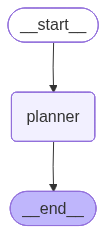

In [ ]:
compiled_planning_graph